# Model Comparison

This notebook compares the three models (*K-Means Clustering*, *K-Nearest Neighbors* and *Multi-Layer Perceptron*) using the three evaluation methods (*Holdout Validation*, *K-Fold Cross Validation* and *Confusion Matrix*).
Each model predicts the policy class of each *province* (`INCREASE = 1`, `RETAIN = 0`, `DECREASE = -1`), and the results are shown as charts using `matplotlib`.

In [37]:
%pip install numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


In [38]:
import csv
import random
from contextlib import redirect_stdout
from io import StringIO
from pathlib import Path
from os import path

import matplotlib.pyplot as plt

from methods.read_data import createMatrix
from methods.normalize_data import standardizeData, coalesceData
from models.clustering import k_means_clustering, distance
from models.mlp import gradient_descent, make_predictions
from evaluation.holdout_validation import holdout_validation
from evaluation.kfold_cross_validation import kFoldSplit, crossValidation, accuracy
from evaluation.conf_matrix import evaluate

with redirect_stdout(StringIO()):               # models/knearest.py prints its own output when imported, so hide it
  from models.knearest import outputMatrix

### Settings
- The same settings are used in all of the evaluation methods, so that the comparison is fair

In [39]:
train_ratio = 0.8       # Holdout validation: 80% training, 20% testing
folds = 5               # K-fold cross validation: number of folds

clusters = 7            # K-means: number of clusters
k = 10                  # K-nearest neighbors: number of neighbors
p = 2                   # K-nearest neighbors: exponent of the distance (2 = Euclidean)
hidden = 20             # MLP: number of neurons in the hidden layer
alpha = 0.05            # MLP: learning rate
iterations = 200        # MLP: number of iterations of gradient descent

### Step 1: Create the Dataset from the `PROJECT_DATASET` folder
- This will create a matrix with 12 fields/attributes and 87 provinces
- Coalesce missing values to 0, then standardize it using Z-score Scaling
- Read the actual class of each province from the tagged dataset `province_policy_results.csv`

In [40]:
data_set_dir = path.join(path.abspath("."), "PROJECT_DATASET")          # Get the path to the dataset folder
provinces, fields, matrix = createMatrix(Path(data_set_dir))            # Create the matrix from the dataset

# Coalesce NA values to 0, then standardize it.
cleaned_data = standardizeData(coalesceData(matrix))
featuresList = [list(row) for row in cleaned_data]                      # Plain lists, so the label can be appended later

# Read the actual class of each province from the tagged dataset
tagged_dir = path.join(data_set_dir, "province_policy_results.csv")    # Get the path to the tagged dataset
with open(tagged_dir, newline="", encoding="utf-8-sig") as file:
  actual_classes = {row["Province"]: row["Class"] for row in csv.DictReader(file)}

# Convert the class of each province to a number, in the same order as provinces
CLASS_TO_LABEL = {"INCREASE": 1, "RETAIN": 0, "DECREASE": -1}
labelList = [CLASS_TO_LABEL[actual_classes[id]] for id in provinces]

CLASSES = (-1, 0, 1)                                                    # Order of the classes in the charts
CLASS_NAMES = {-1: "DECREASE", 0: "RETAIN", 1: "INCREASE"}

print(f"{len(provinces)} provinces, {len(featuresList[0])} features each")
for label in CLASSES:
  print(f"{CLASS_NAMES[label]:<9}: {labelList.count(label)}")

87 provinces, 12 features each
DECREASE : 10
RETAIN   : 31
INCREASE : 46


### Step 2: Wrap each model in one function
- Holdout validation and k-fold cross validation both accept a `model(testing_rows, training_list)` function
- `training_list` has the true label as the last element of each row, and `testing_rows` has the features only
- Each function returns the testing rows with the predicted label added as the last element
- **K-Nearest Neighbors**: the predicted class is the most common class among the k nearest training rows
- **MLP**: the network is trained on the training rows, then it predicts the testing rows
- **K-Means**: it is *unsupervised*, so the training rows are clustered first, each cluster is labeled with the most common actual class among its rows (majority vote), and a testing row gets the label of its nearest centroid

In [41]:
def knn_model(testing_rows, training_list):
  return outputMatrix(testing_rows, training_list, k, p)

def mlp_model(testing_rows, training_list):
  index = {label: i for i, label in enumerate(CLASSES)}       # {-1: 0, 0: 1, 1: 2}
  X_train = [row[:-1] for row in training_list]               # Features only
  Y_train = [index[row[-1]] for row in training_list]         # Labels as class indices

  random.seed(1)                                              # Same starting weights every run
  with redirect_stdout(StringIO()):                           # Hide the training progress
    w1, b1, w2, b2 = gradient_descent(X_train, Y_train, alpha=alpha, iterations=iterations, hiddenNum=hidden, outputNum=len(CLASSES))

  predictions = make_predictions(testing_rows, w1, b1, w2, b2)
  return [testing_rows[i] + [CLASSES[predictions[i]]] for i in range(len(testing_rows))]

def kmeans_model(testing_rows, training_list):
  train_stats = {i: training_list[i][:-1] for i in range(len(training_list))}   # Features only, row position as id
  train_labels = {i: training_list[i][-1] for i in range(len(training_list))}

  random.seed(1)                                              # Same starting centroids every run
  with redirect_stdout(StringIO()):                           # Hide the centroids
    categories = k_means_clustering(train_stats, clusters)

  # Get the centroid and the label (majority vote) of each cluster
  centroids = []
  cluster_labels = []
  for cluster in sorted(set(categories.values())):
    members = [id for id in categories if categories[id] == cluster]
    centroids.append([sum(train_stats[id][dim] for id in members) / len(members) for dim in range(len(testing_rows[0]))])
    member_labels = [train_labels[id] for id in members]
    cluster_labels.append(max(member_labels, key=member_labels.count))

  # A testing row gets the label of its nearest centroid
  output = []
  for row in testing_rows:
    distances = [distance(row, centroid) for centroid in centroids]
    output.append(row + [cluster_labels[distances.index(min(distances))]])
  return output

MODELS = {"K-Means": kmeans_model, "K-Nearest Neighbors": knn_model, "MLP": mlp_model}

### Chart settings
- Each model has its own color, and the same color is used for the model in all of the charts

In [42]:
MODEL_COLORS = {"K-Means": "#082a54", "K-Nearest Neighbors": "#e02b35", "MLP": "#ea801c"}
TEXT_COLOR = "#0b0b0b"
MUTED_COLOR = "#52514e"
GRID_COLOR = "#e4e3df"

plt.rcParams.update({
  "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
  "text.color": TEXT_COLOR, "axes.labelcolor": MUTED_COLOR, "xtick.color": MUTED_COLOR, "ytick.color": MUTED_COLOR,
  "axes.edgecolor": GRID_COLOR, "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10,
})

def grouped_bars(ax, groups, values, title, percent=True):
  """
  Draws one bar per model for each group
  Args:
  - ax: The axes where the bars are drawn
  - groups: List of the group names (x-axis)
  - values: Dictionary of model name -> list of values, same order as groups
  - title: Title of the chart
  """
  width = 0.8 / len(values)                                   # Width of one bar
  for m, (name, model_values) in enumerate(values.items()):
    positions = [g + (m - (len(values) - 1) / 2) * width for g in range(len(groups))]
    bars = ax.bar(positions, model_values, width * 0.92, label=name, color=MODEL_COLORS[name])
    for bar, value in zip(bars, model_values):                # Write the value above each bar
      text = f"{value:.0%}" if percent else f"{value:.2f}"
      ax.text(bar.get_x() + bar.get_width() / 2, value + 0.015, text, ha="center", va="bottom", fontsize=8, color=TEXT_COLOR)
  ax.set_xticks(range(len(groups)))
  ax.set_xticklabels(groups)
  ax.set_ylim(0, 1.12)
  ax.set_yticks([0, 0.25, 0.5, 0.75, 1])
  ax.set_yticklabels(["0%", "25%", "50%", "75%", "100%"] if percent else ["0", "0.25", "0.50", "0.75", "1.00"])
  ax.yaxis.grid(True, color=GRID_COLOR, linewidth=0.8)
  ax.set_axisbelow(True)
  ax.tick_params(length=0)
  for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
  ax.set_title(title, loc="left")

### Step 3: Holdout Validation
- 80% of the provinces are used for training and the remaining 20% for testing
- The split is seeded, so all of the models are trained and tested on the same provinces
- The accuracy is the number of testing provinces with a correct prediction, over the number of testing provinces

In [43]:
holdout_results = {}
for name, model in MODELS.items():
  # Each result is a tuple (province index, true label, predicted label, fold)
  holdout_results[name] = holdout_validation(featuresList, labelList, train_ratio, model)

test_size = len(holdout_results["K-Means"])
print(f"Training provinces: {len(provinces) - test_size}, Testing provinces: {test_size}\n")
for name, results in holdout_results.items():
  correct = sum(result[1] == result[2] for result in results)
  print(f"{name:<20} {correct}/{len(results)} = {accuracy(results):.2%}")

Training provinces: 70, Testing provinces: 17

K-Means              11/17 = 64.71%
K-Nearest Neighbors  14/17 = 82.35%
MLP                  13/17 = 76.47%


### Step 4: K-Fold Cross Validation
- The provinces are split into 5 folds, each fold is the testing set once and the other folds are the training set
- Every province is predicted exactly once, so the accuracy uses all of the 87 provinces
- The accuracy of each fold shows how much the result of a model changes with the provinces used for training

In [44]:
foldList = kFoldSplit(len(featuresList), folds)

kfold_results = {}
for name, model in MODELS.items():
  # Each result is a tuple (province index, true label, predicted label, fold)
  kfold_results[name] = crossValidation(featuresList, labelList, foldList, model)

# Accuracy of each fold for each model
fold_accuracy = {}
for name, results in kfold_results.items():
  fold_accuracy[name] = [accuracy([result for result in results if result[3] == f + 1]) for f in range(folds)]

print(f"{'Model':<20} " + " ".join(f"{'Fold ' + str(f + 1):>8}" for f in range(folds)) + f" {'Overall':>8}")
for name, results in kfold_results.items():
  print(f"{name:<20} " + " ".join(f"{value:>8.2%}" for value in fold_accuracy[name]) + f" {accuracy(results):>8.2%}")

Model                  Fold 1   Fold 2   Fold 3   Fold 4   Fold 5  Overall
K-Means                83.33%   61.11%   76.47%   58.82%   70.59%   70.11%
K-Nearest Neighbors    83.33%   72.22%   82.35%   64.71%   70.59%   74.71%
MLP                    83.33%   72.22%   88.24%   58.82%   82.35%   77.01%


### Step 5: Compare the accuracy of the models
- The first chart compares the accuracy of each model under holdout validation and k-fold cross validation
- The second chart shows the accuracy of each model in each fold

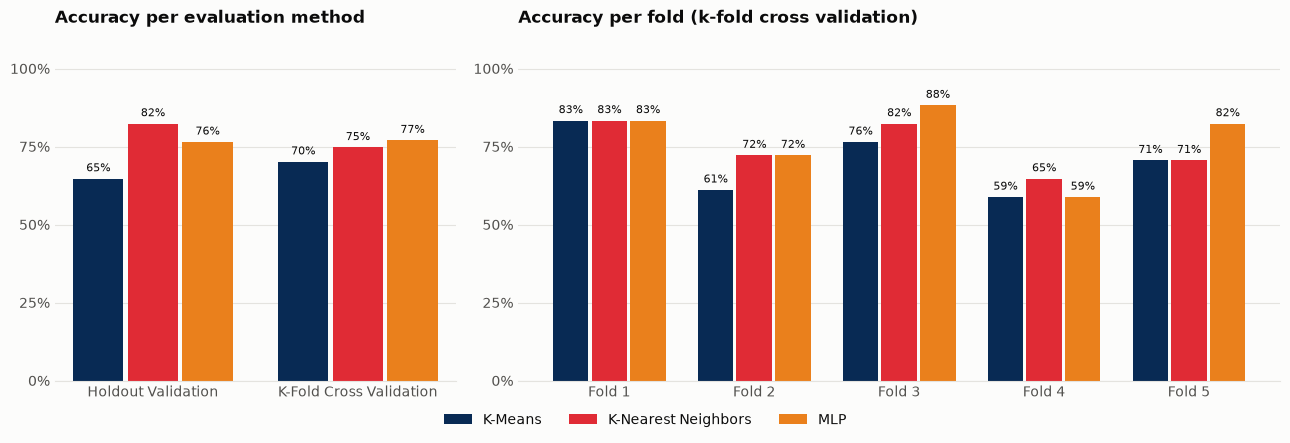

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 1.9]})

# Accuracy under holdout validation and k-fold cross validation
grouped_bars(axes[0], ["Holdout Validation", "K-Fold Cross Validation"],
             {name: [accuracy(holdout_results[name]), accuracy(kfold_results[name])] for name in MODELS},
             "Accuracy per evaluation method")

# Accuracy of each fold
grouped_bars(axes[1], [f"Fold {f + 1}" for f in range(folds)], fold_accuracy, "Accuracy per fold (k-fold cross validation)")

handles, names = axes[0].get_legend_handles_labels()
fig.legend(handles, names, loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.06))
fig.tight_layout()
plt.show()

### Step 6: Confusion Matrix
- The predictions from the k-fold cross validation are used, since every province has a prediction
- Each row is the actual class and each column is the predicted class, so the correct predictions are in the diagonal
- A darker cell means more provinces

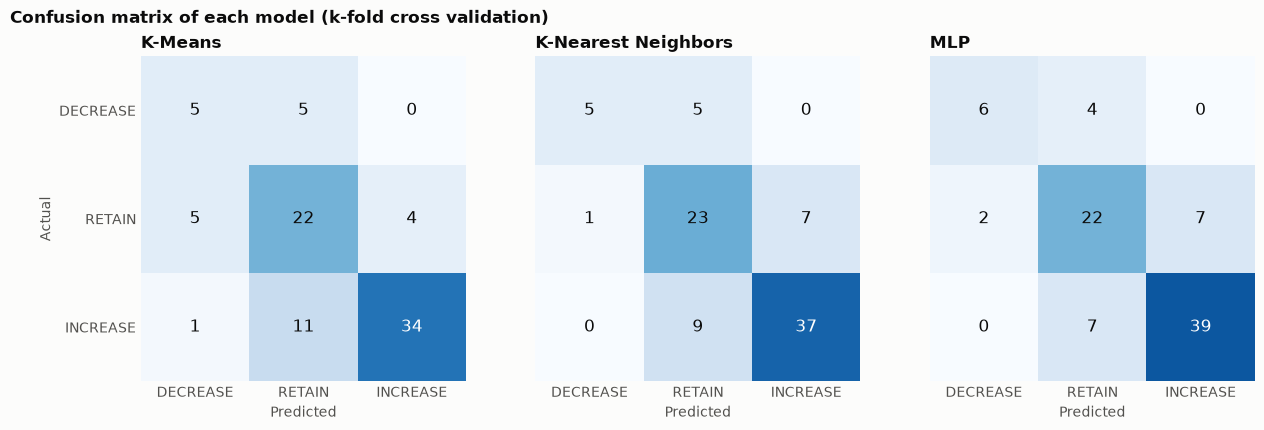

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
names = [CLASS_NAMES[label] for label in CLASSES]

for ax, (name, results) in zip(axes, kfold_results.items()):
  # counts[actual][predicted] = number of provinces
  counts = [[0] * len(CLASSES) for _ in CLASSES]
  for result in results:
    counts[CLASSES.index(result[1])][CLASSES.index(result[2])] += 1

  ax.imshow(counts, cmap="Blues", vmin=0, vmax=labelList.count(1))
  for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):                             # Write the count in each cell
      ax.text(j, i, counts[i][j], ha="center", va="center", fontsize=12,
              color="white" if counts[i][j] > labelList.count(1) * 0.55 else TEXT_COLOR)
  ax.set_xticks(range(len(CLASSES)))
  ax.set_xticklabels(names)
  ax.set_yticks(range(len(CLASSES)))
  ax.set_yticklabels(names if ax is axes[0] else [])
  ax.set_xlabel("Predicted")
  ax.tick_params(length=0)
  for side in ax.spines.values():
    side.set_visible(False)
  ax.set_title(name, loc="left", color=TEXT_COLOR)

axes[0].set_ylabel("Actual")
fig.suptitle("Confusion matrix of each model (k-fold cross validation)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

### Step 7: Compare the performance metrics of the models
- `evaluate` computes the Recall, Precision and F1 Score of each class (one vs. rest) from the confusion matrix
- **Recall**: out of the provinces that are actually in the class, how many were predicted correctly
- **Precision**: out of the provinces that were predicted as the class, how many are actually in the class
- **F1 Score**: the balance of the recall and the precision

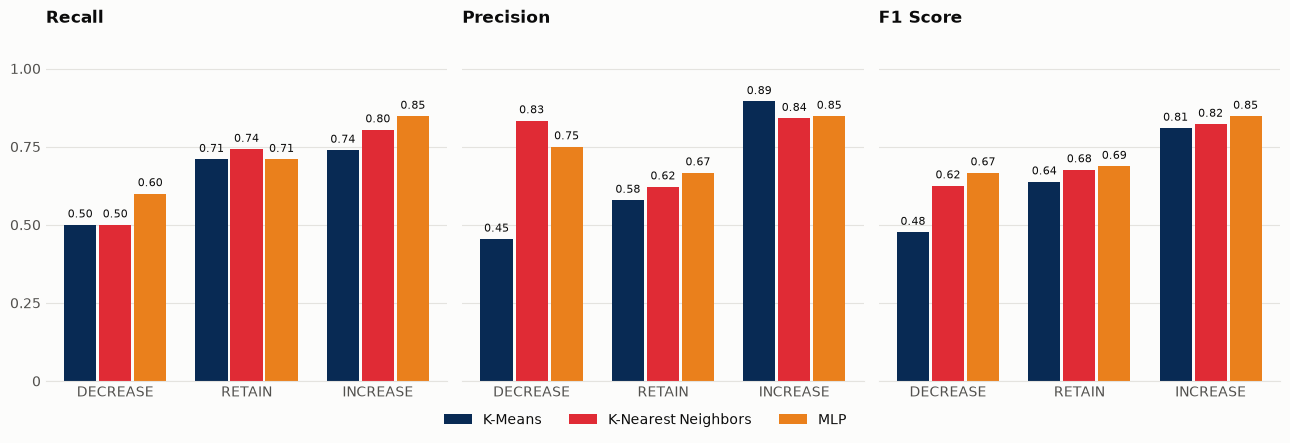

In [47]:
metrics = {}
for name, results in kfold_results.items():
  actual = [result[1] for result in results]                  # Actual class from the tagged dataset
  predicted = [result[2] for result in results]               # Predicted class from the model
  with redirect_stdout(StringIO()):                           # Hide the printed matrices, the charts show them
    metrics[name] = evaluate(actual, predicted)

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharey=True)
for ax, (metric, title) in zip(axes, [("recall", "Recall"), ("precision", "Precision"), ("f1_score", "F1 Score")]):
  values = {name: [metrics[name][label][metric] if label in metrics[name] else 0 for label in CLASSES] for name in MODELS}
  grouped_bars(ax, names, values, title, percent=False)

handles, legend_names = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_names, loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.06))
fig.tight_layout()
plt.show()

### Step 8: Summary
- The table shows the accuracy of each model under holdout validation and k-fold cross validation, and the average F1 Score of the three classes from the confusion matrix
- The average F1 Score treats the three classes equally, so a model that ignores the `DECREASE` class (which has the fewest provinces) gets a lower score even when its accuracy is high

In [48]:
print(f"{'Model':<20} {'Holdout':>9} {'K-Fold':>9} {'Average F1':>11}")
summary = {}
for name in MODELS:
  average_f1 = sum(metrics[name][label]["f1_score"] if label in metrics[name] else 0 for label in CLASSES) / len(CLASSES)
  summary[name] = (accuracy(holdout_results[name]), accuracy(kfold_results[name]), average_f1)
  print(f"{name:<20} {summary[name][0]:>9.2%} {summary[name][1]:>9.2%} {summary[name][2]:>11.4f}")

print()
for position, title in enumerate(["Holdout Validation", "K-Fold Cross Validation", "Confusion Matrix (average F1)"]):
  best = max(summary, key=lambda name: summary[name][position])
  print(f"Highest in {title}: {best}")

Model                  Holdout    K-Fold  Average F1
K-Means                 64.71%    70.11%      0.6411
K-Nearest Neighbors     82.35%    74.71%      0.7079
MLP                     76.47%    77.01%      0.7340

Highest in Holdout Validation: K-Nearest Neighbors
Highest in K-Fold Cross Validation: MLP
Highest in Confusion Matrix (average F1): MLP
